# Basic Image Filtering

using:
- binary threshold
- adaptive threshold
- Lowpass blur filter with kernel and convulational 2D
- Highpass Filter with Sobel

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

from cv_utils import (
    display,
    display_grid,
    ImageLoader
)

# Loading img with different CMaps

In [2]:
import os
from pathlib import Path
from dotenv import load_dotenv

load_dotenv()
PROJECT_ROOT = Path(os.getenv("PROJECT_ROOT"))
DATA_DIR = Path(os.getenv("DATA_DIR"))

giraffes_path = DATA_DIR.joinpath("giraffes.jpg")
giraffes_path.exists()

True

In [3]:
img_org, img_gs, img_hsv, img_rgb = ImageLoader.load_bgr_gs_hsv_rgb(giraffes_path)

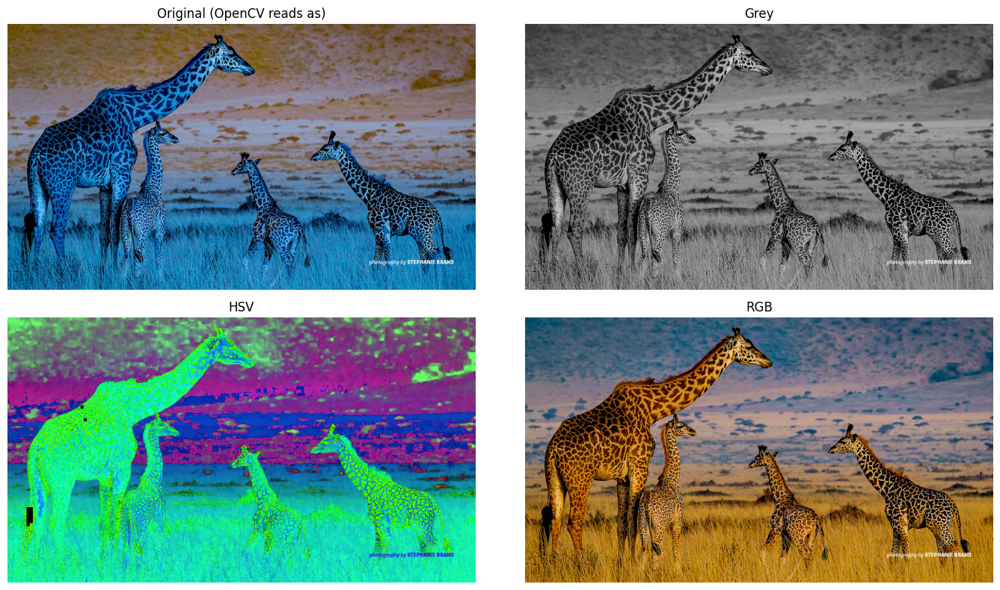

In [4]:
titles = ["Original (OpenCV reads as)", "Grey", "HSV", "RGB" ]

display_grid([img_org, img_gs, img_hsv, img_rgb], cmap="gray", max_cols=2, titles=titles)

## Binary threshold Filter

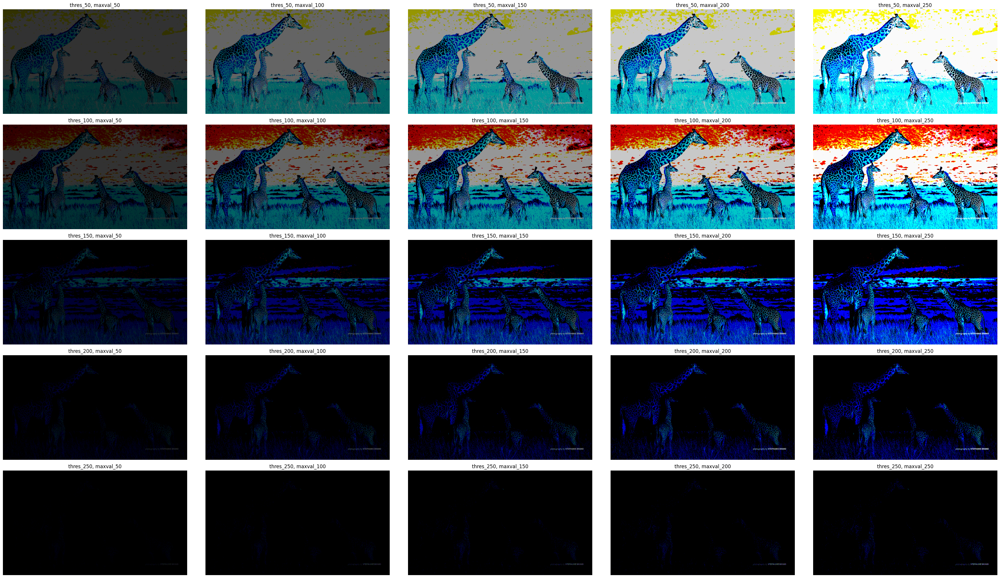

In [5]:
binary_results = {}

for threshold in range(50, 255, 50):
    for maxval in range(50, 255, 50):
        _, img = cv2.threshold(img_org,
                                  threshold,
                                  maxval,
                                  cv2.THRESH_BINARY)

        title = f"thres_{threshold}, maxval_{maxval}"
        binary_results[title] = img

display_grid(images=list(binary_results.values()), titles=list(binary_results.keys()), max_cols=5)

## adaptive threshold filters

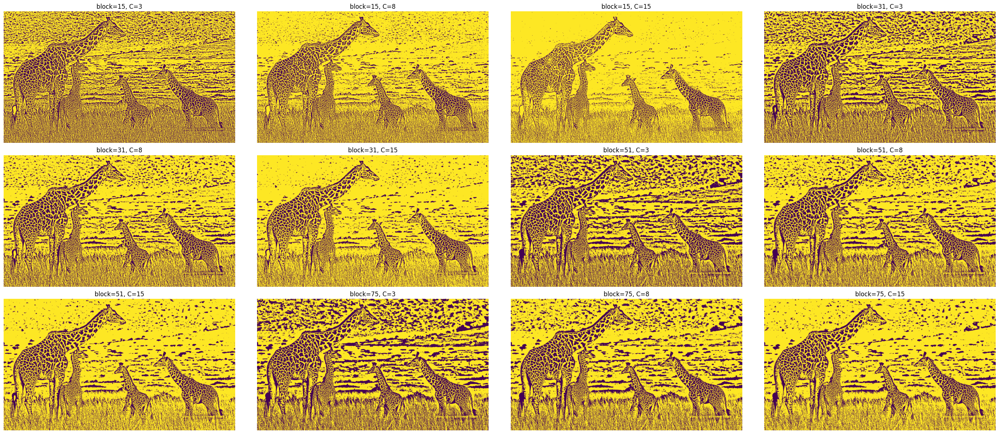

In [6]:
adaptive_results = {}

for bs in [15, 31, 51, 75]:
    for c in [3, 8, 15]:
        mask = cv2.adaptiveThreshold(
            img_gs, 255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY,
            bs, c
        )
        adaptive_results[f"block={bs}, C={c}"] = mask

display_grid(images=list(adaptive_results.values()),
             titles=list(adaptive_results.keys()),
             max_cols=4)

## Lowpass Blur filter with kernel and convulutional 2D

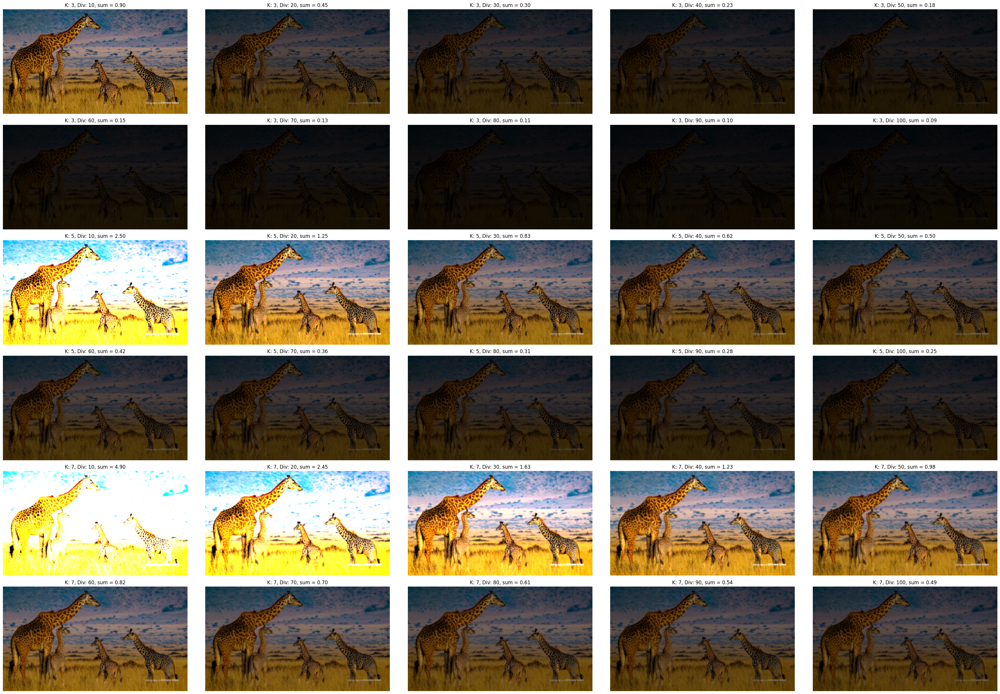

In [7]:
# Test different lowpass filters using division on kernels

conv_results = {}

for k in range(3, 8, 2):
    for divide in range(10, 101, 10):
        kernel = np.ones(shape=(k, k), dtype=np.float32) / divide
        img = cv2.filter2D(img_rgb, -1, kernel)
        conv_results[f"K: {k}, Div: {divide}, sum = {kernel.sum():.2f}"] = img


display_grid(images=list(conv_results.values()),
             titles=list(conv_results.keys()),
             max_cols=5
)

# Highpass filter with Sobel

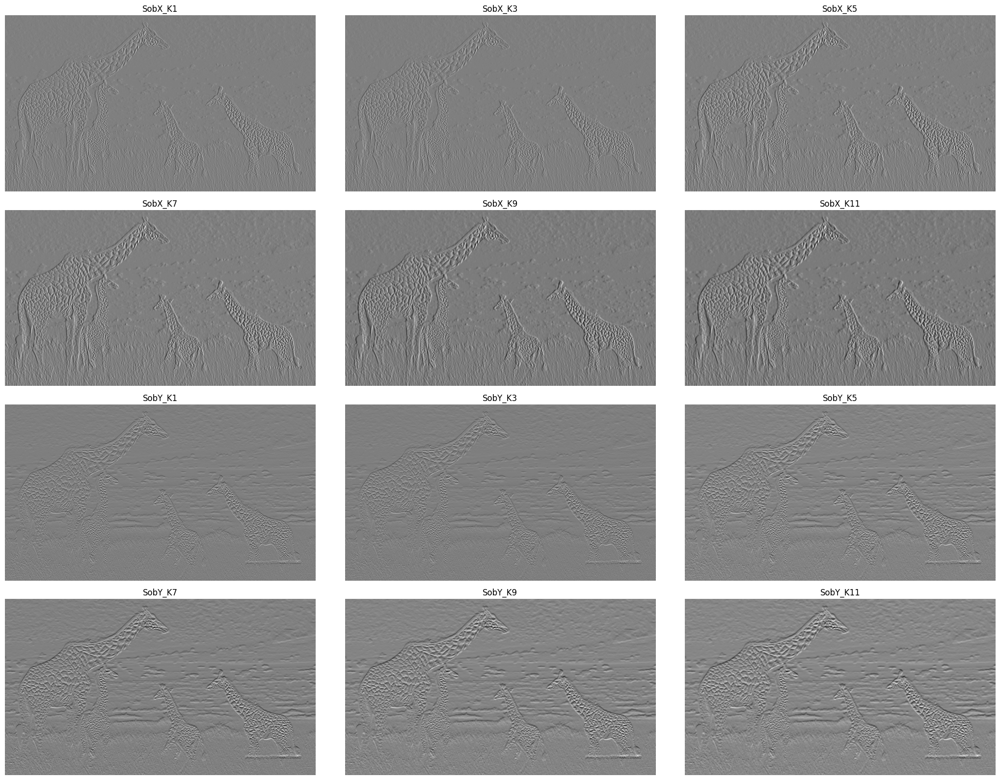

In [10]:
imgs = {}
for ksize in range(1, 12, 2):
    sobel_x = cv2.Sobel(img_gs, cv2.CV_64F, 1, 0, ksize=ksize)
    title = f"SobX_K{ksize}"
    imgs[title] = sobel_x

for ksize in range(1, 12, 2):
    sobel_y = cv2.Sobel(img_gs, cv2.CV_64F, 0, 1, ksize=ksize)
    title = f"SobY_K{ksize}"
    imgs[title] = sobel_y


display_grid(list(imgs.values()), cmap="gray", max_cols=3, titles=list(imgs.keys()))